In [2]:
%matplotlib inline


# Plotting shots

Start by watching the video below, then learn how to plot shot positions.

..  youtube:: GWsK_KWKCas
   :width: 640
   :height: 349


In [4]:
import matplotlib.pyplot as plt
import numpy as np
from mplsoccer import Pitch, Sbopen, VerticalPitch
import mplsoccer
import sympy as sp
from scipy.interpolate import griddata

## Opening the dataset
The first thing we have to do is open the data. We use a parser SBopen available in mplsoccer.
Using method *event* and putting the id of the game as a parameter we load the data.
The event data, which we will mostly focus on,
is stored in a dataframe *df*. From this dataframe we take out the names of the two teams.
Then, we filter the dataframe so that only shots are left.



In [5]:
parser = Sbopen()
df, related, freeze, tactics = parser.event(69301)
#get team names
team1, team2 = df.team_name.unique()
#A dataframe of shots
shots = df.loc[df['type_name'] == 'Shot'].set_index('id')

## Making the shot map using iterative solution
First let's draw the pitch using the [MPL Soccer class](https://mplsoccer.readthedocs.io/en/latest/gallery/pitch_setup/plot_pitches.html),

In this example, we set variables for pitch length and width to the Statsbomb coordinate system (they use yards).
You can read more about [different coordinate systems here](https://mplsoccer.readthedocs.io/en/latest/gallery/pitch_setup/plot_compare_pitches.html)

Now, we iterate through all the shots in the match. We take *x* and *y* coordinates, the team name and information
if goal was scored. If It was scored, we plot a solid circle with a name of the player, if not, we plot a
transculent circle (parameter alpha tunes the transcluency).
To have England's shots on one half and Sweden shots on the other half,
we subtract *x* and *y* from the pitch length and height.

Football data tends to be attacking left to right, and we will use this as default in the course.



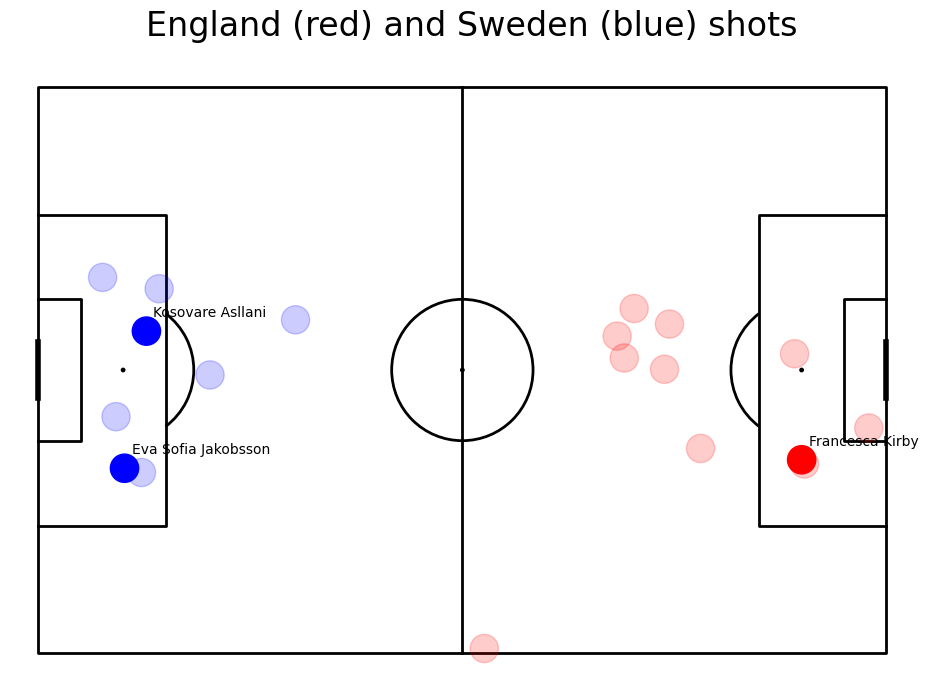

In [6]:
pitch = Pitch(line_color = "black")
fig, ax = pitch.draw(figsize=(10, 7))
#Size of the pitch in yards (!!!)
pitchLengthX = 120
pitchWidthY = 80
#Plot the shots by looping through them.
for i,shot in shots.iterrows():
    #get the information 
    x=shot['x']
    y=shot['y']
    goal=shot['outcome_name']=='Goal'
    team_name=shot['team_name']    
    #set circlesize
    circleSize=2
    #plot England
    if (team_name==team1):
        if goal:
            shotCircle=plt.Circle((x,y),circleSize,color="red")
            plt.text(x+1,y-2,shot['player_name']) 
        else:
            shotCircle=plt.Circle((x,y),circleSize,color="red")     
            shotCircle.set_alpha(.2)
    #plot Sweden
    else:
        if goal:
            shotCircle=plt.Circle((pitchLengthX-x,pitchWidthY - y),circleSize,color="blue") 
            plt.text(pitchLengthX-x+1,pitchWidthY - y - 2 ,shot['player_name'])
        else:
            shotCircle=plt.Circle((pitchLengthX-x,pitchWidthY - y),circleSize,color="blue")      
            shotCircle.set_alpha(.2)
    ax.add_patch(shotCircle)
#set title
fig.suptitle("England (red) and Sweden (blue) shots", fontsize = 24)     
fig.set_size_inches(10, 7)
plt.show()

## Using mplsoccer's Pitch class
This time we make a direct query to return only shots by each team.
We only need the columns with cooridnates, outcome (showing if goal was scored),
and player name. If a goal was scored, we use scatter method
to plot a circle and annotate method to mark scorer's name.
If not, we use scatter method to draw a translucent circle. 
Note that, once again, to plot the shots on different halves we needed to reverse the coordinates for Sweden.
Using pitch.scatter we could have plotted all shots using one line. 
However, since name of a player and alpha differs if goal was scored,
it was more convenient to loop through smaller dataset.



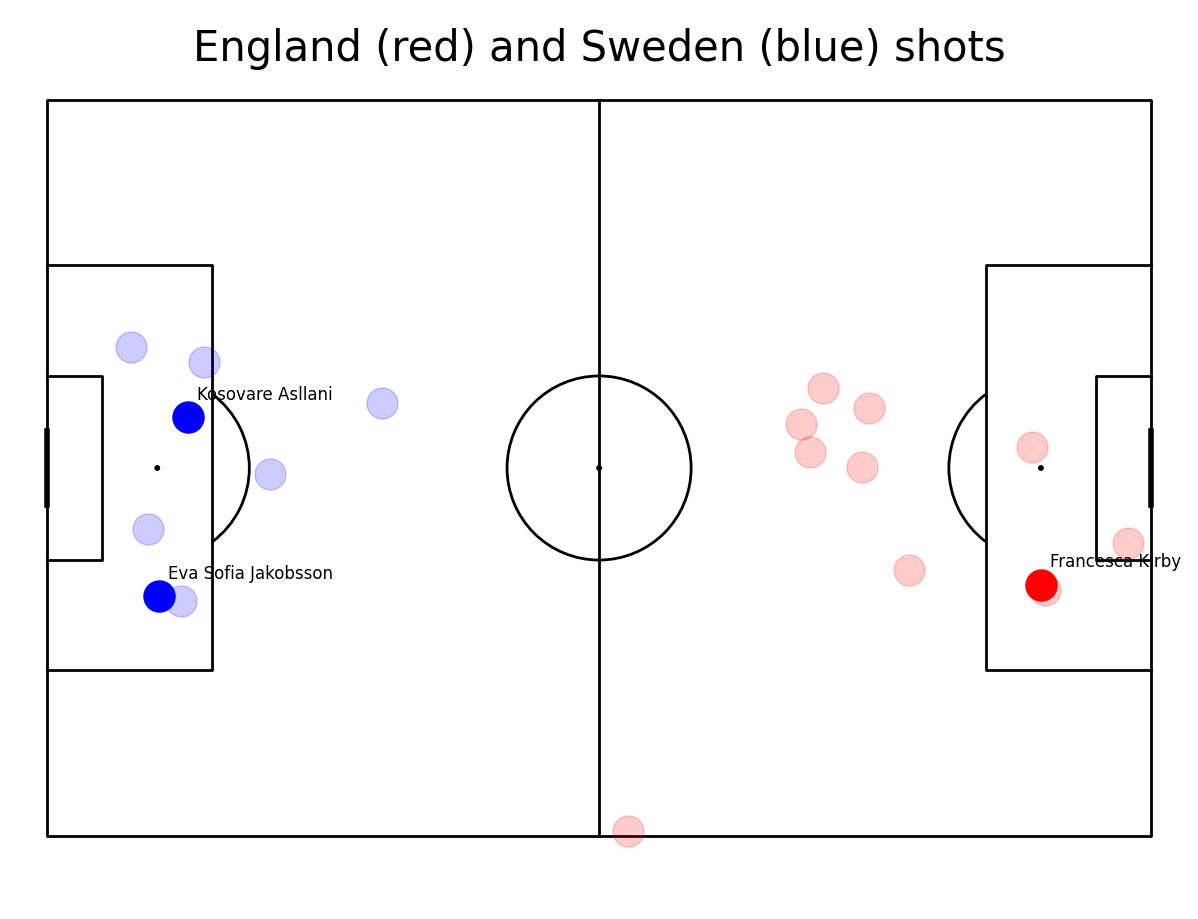

In [7]:
#create pitch
pitch = Pitch(line_color='black')
fig, ax = pitch.grid(grid_height=0.9, title_height=0.06, axis=False,
                     endnote_height=0.04, title_space=0, endnote_space=0)
#query
mask_england = (df.type_name == 'Shot') & (df.team_name == team1)
#finding rows in the df and keeping only necessary columns
df_england = df.loc[mask_england, ['x', 'y', 'outcome_name', "player_name"]]

#plot them - if shot ended with Goal - alpha 1 and add name
#for England
for i, row in df_england.iterrows():
    if row["outcome_name"] == 'Goal':
    #make circle 
       pitch.scatter(row.x, row.y, alpha = 1, s = 500, color = "red", ax=ax['pitch']) 
       pitch.annotate(row["player_name"], (row.x + 1, row.y - 2), ax=ax['pitch'], fontsize = 12)
    else: 
       pitch.scatter(row.x, row.y, alpha = 0.2, s = 500, color = "red", ax=ax['pitch']) 
       
mask_sweden = (df.type_name == 'Shot') & (df.team_name == team2)
df_sweden = df.loc[mask_sweden, ['x', 'y', 'outcome_name', "player_name"]]   

#for Sweden we need to revert coordinates
for i, row in df_sweden.iterrows():
    if row["outcome_name"] == 'Goal':
       pitch.scatter(120 - row.x, 80 - row.y, alpha = 1, s = 500, color = "blue", ax=ax['pitch']) 
       pitch.annotate(row["player_name"], (120 - row.x + 1, 80 - row.y - 2), ax=ax['pitch'], fontsize = 12)
    else: 
       pitch.scatter(120 - row.x, 80 - row.y, alpha = 0.2, s = 500, color = "blue", ax=ax['pitch']) 
       
fig.suptitle("England (red) and Sweden (blue) shots", fontsize = 30)           
plt.show()

## Plotting shots on one half
To plot shots of only one team on one half we use VerticalPitch() class
If you set *half* to *True*, you will plot only one half of the pitch.
It is a nice way of plotting shots since they rarely occur on the defensive half.
We plot all the shots at once this time, without looping through the dataframe this time.



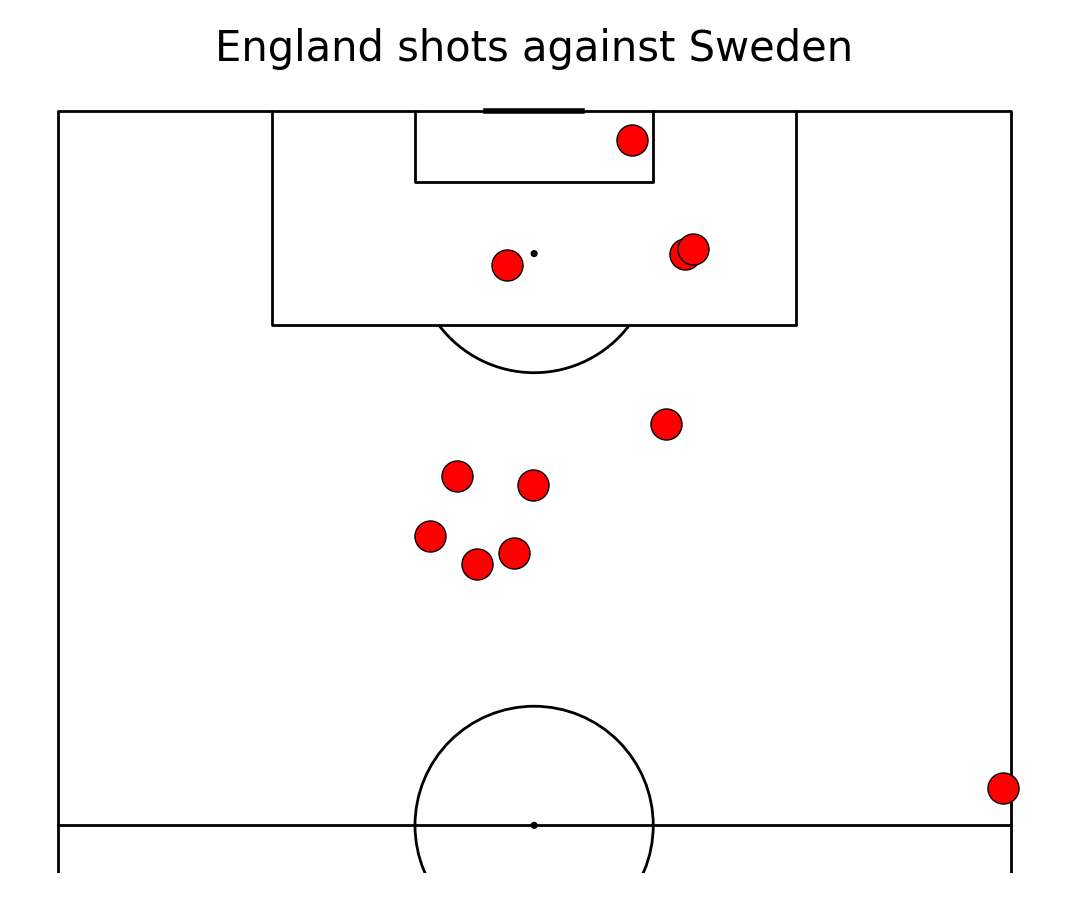

In [8]:
pitch = VerticalPitch(line_color='black', half = True)
fig, ax = pitch.grid(grid_height=0.9, title_height=0.06, axis=False,
                     endnote_height=0.04, title_space=0, endnote_space=0)
#plotting all shots
pitch.scatter(df_england.x, df_england.y, alpha = 1, s = 500, color = "red", ax=ax['pitch'], edgecolors="black") 
fig.suptitle("England shots against Sweden", fontsize = 30)           
plt.show()

## Challenge - try it before looking at the next page
1) Create a dataframe of passes which contains all the passes in the match
2) Plot the start point of every Sweden pass. Attacking left to right.
3) Plot only passes made by Caroline Seger (she is Sara Caroline Seger in the database)
4) Plot arrows to show where the passes went to.



In [9]:
parser = Sbopen()
df, related, freeze, tactics = parser.event(69301)
#get team names
team1, team2 = df.team_name.unique()
#A dataframe of shots
shots = df.loc[df['type_name'] == 'Pass'].set_index('id')

In [10]:
df.columns

Index(['id', 'index', 'period', 'timestamp', 'minute', 'second', 'possession',
       'duration', 'match_id', 'type_id', 'type_name', 'possession_team_id',
       'possession_team_name', 'play_pattern_id', 'play_pattern_name',
       'team_id', 'team_name', 'tactics_formation', 'player_id', 'player_name',
       'position_id', 'position_name', 'pass_recipient_id',
       'pass_recipient_name', 'pass_length', 'pass_angle', 'pass_height_id',
       'pass_height_name', 'end_x', 'end_y', 'body_part_id', 'body_part_name',
       'sub_type_id', 'sub_type_name', 'x', 'y', 'under_pressure',
       'outcome_id', 'outcome_name', 'out', 'counterpress', 'pass_deflected',
       'pass_switch', 'technique_id', 'technique_name', 'pass_cross',
       'off_camera', 'shot_statsbomb_xg', 'end_z', 'shot_first_time',
       'goalkeeper_position_id', 'goalkeeper_position_name',
       'ball_recovery_recovery_failure', 'pass_assisted_shot_id',
       'pass_shot_assist', 'shot_key_pass_id', 'foul_won_defensiv

In [16]:
shot

index                                  3287
period                                    2
timestamp                   00:49:19.754000
minute                                   94
second                                   19
                                 ...       
block_save_block                        NaN
foul_committed_advantage                NaN
foul_won_advantage                      NaN
foul_committed_card_id                  NaN
foul_committed_card_name                NaN
Name: 95dc3f18-7494-4b78-b7bd-c07845c55b72, Length: 72, dtype: object

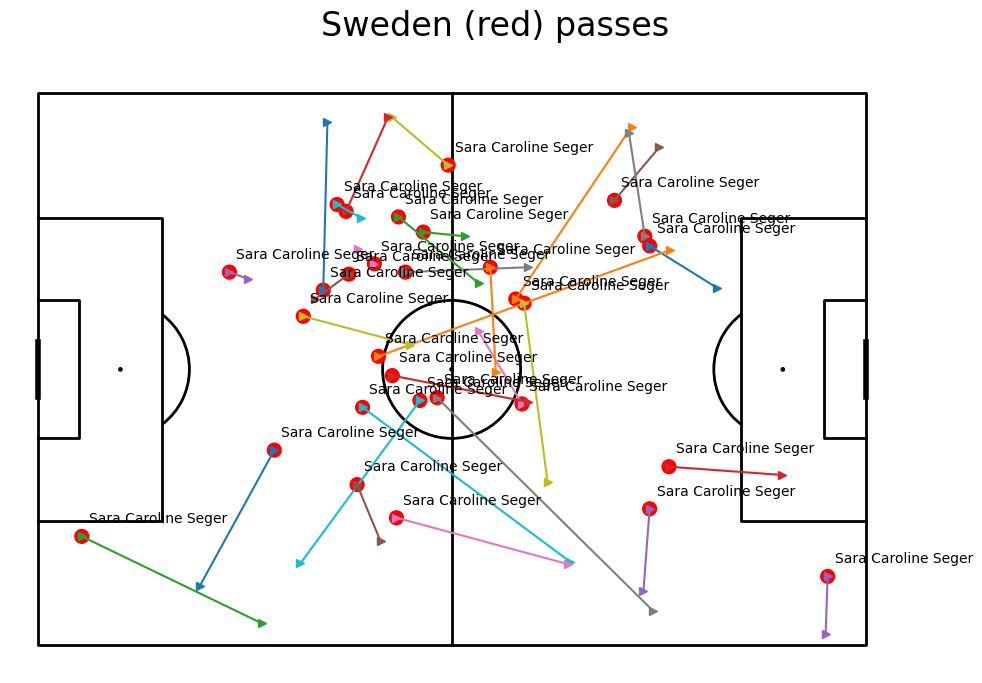

In [13]:
pitch = Pitch(line_color = "black")
fig, ax = pitch.draw(figsize=(10, 7))
#Size of the pitch in yards (!!!)
pitchLengthX = 120
pitchWidthY = 80
prev=0
count=0
posx=[]
posy=[]
#Plot the shots by looping through them.
for i,shot in shots.iterrows():
    #get the information 
    x=shot['x']
    y=shot['y']
    endx=shot['end_x']
    endy=shot['end_y']
    goal=shot['outcome_name']=='Pass'
    team_name=shot['team_name']
    player=shot['player_name']=='Sara Caroline Seger'
    #set circlesize
    circleSize=1
    #plot Sweden
    if (team_name==team2):
        if player:
            shotCircle=plt.Circle((x,y),circleSize,color="red")
            plt.text(x+1,y-2,shot['player_name'])
            ax.add_patch(shotCircle)
            count=count+1
            posx.append(x)
            posy.append(y)
            posx.append(endx)
            posy.append(endy)
    
            
#            plt.plot()
            
            
            
#            plt.arrow(x,y,10,10,head_width=3,head_length=2)
'''
        else:
            shotCircle=plt.Circle((x,y),circleSize,color="red")     
            shotCircle.set_alpha(.2)
 #           plt.arrow(x+1,y-2,5,1)
 

    #plot England
    else:
        continue
        if goal:
            shotCircle=plt.Circle((pitchLengthX-x,pitchWidthY - y),circleSize,color="blue") 
            plt.text(pitchLengthX-x+1,pitchWidthY - y - 2 ,shot['player_name'])
 #           plt.arrow(x+1,y-2,5,1)
        else:
            shotCircle=plt.Circle((pitchLengthX-x,pitchWidthY - y),circleSize,color="blue")      
            shotCircle.set_alpha(.2)
 #           plt.arrow(x+1,y-2,5,1)
'''


#set title
for i in range(0, len(posx), 2):
    plt.plot(posx[i:i+2], posy[i:i+2], '->')
    
fig.suptitle("Sweden (red) passes", fontsize = 24)     
fig.set_size_inches(10, 7)
plt.show()

# ATTEMPT-2

# USING CONTENT FROM MAD ABOUT SPORTS

In [9]:
df1=df[df["type_name"]=="Pass"]

df2=df1[df1["team_name"]=="Sweden Women's"]

df3=df2[df2["player_name"]=="Sara Caroline Seger"]

pitch=mplsoccer.Pitch(pitch_type='statsbomb',pitch_color='white',line_color='black')
fig,ax=pitch.draw(figsize=(14,8))
pitch.arrows(df2['x'],df2['y'],df2['end_x'],df2['end_y'],alpha=0.6,width=3,ax=ax,color='blue')
plt.show()

In [13]:
df1.columns

Index(['id', 'index', 'period', 'timestamp', 'minute', 'second', 'possession',
       'duration', 'match_id', 'type_id', 'type_name', 'possession_team_id',
       'possession_team_name', 'play_pattern_id', 'play_pattern_name',
       'team_id', 'team_name', 'tactics_formation', 'player_id', 'player_name',
       'position_id', 'position_name', 'pass_recipient_id',
       'pass_recipient_name', 'pass_length', 'pass_angle', 'pass_height_id',
       'pass_height_name', 'end_x', 'end_y', 'body_part_id', 'body_part_name',
       'sub_type_id', 'sub_type_name', 'x', 'y', 'under_pressure',
       'outcome_id', 'outcome_name', 'out', 'counterpress', 'pass_deflected',
       'pass_switch', 'technique_id', 'technique_name', 'pass_cross',
       'off_camera', 'shot_statsbomb_xg', 'end_z', 'shot_first_time',
       'goalkeeper_position_id', 'goalkeeper_position_name',
       'ball_recovery_recovery_failure', 'pass_assisted_shot_id',
       'pass_shot_assist', 'shot_key_pass_id', 'foul_won_defensiv

# TRYING TO ANALYSE THE VECTOR FIELD OF PASSES

In [75]:
# Iterating using itertuples()
VFLD=[]
V=[]
Starting_point=[]
for row in df1.itertuples():
    #total_sales = row.Quantity * row.Price
    v1=[row.end_x-row.x,row.end_y-row.y]
    Starting_point.append([row.x,row.y])
    VFLD.append([row.x,row.y,v1])
    V.append(v1)

df1['pass vector']=V


/var/folders/z_/lxkyxgq53_54hftk7vv3kdg80000gn/T/ipykernel_675/2965389235.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['pass vector']=V


In [89]:
x = list(np.arange(0,130,15)) 
y = list(np.arange(0,90,15))
Zones=[]
for i in range(len(x)-1):
    for j in range(len(y)-1):
        Zones.append([x[i],x[i+1],y[j],y[j+1]])



# BRUTEFORCE CODE TO SELECT THE VECTORS IN EACH ZONE

In [104]:
#GETTING THE LOCATIONS OF CO-ORDINATES
x2=df1.columns.get_loc('end_x')
x1=df1.columns.get_loc('x')
y1=df1.columns.get_loc('y')
y2=df1.columns.get_loc('end_y')
v=df1.columns.get_loc('pass vector')

In [91]:
#CHOOSING THE RESPECTIVE ACTIONS IN EACH ZONE
Zone_action=[]
for i in range(len(Zones)):
    a=Zones[i][0]
    b=Zones[i][1]
    c=Zones[i][2]
    d=Zones[i][3]
    zone_temp=[]
    for j in range(len(df1)):
        A=list(df1.iloc[j])
        if (A[x1]>=a) and (A[x1]<=b):
            if (A[y1]>=c) and (A[y1]<=d):
                zone_temp.append(A[v])
    Zone_action.append(zone_temp)    
        
    

In [98]:
#NET VECTOR FOR EACH ZONE
Zone_action_net=[]
for i in range(len(Zone_action)):
    a=Zone_action[i]
    X=[m[0] for m in a]
    Y=[m[1] for m in a]
    if len(X)!=0:
        Xavg=sum(X)/len(X)
        Yavg=sum(Y)/len(Y)
    else:
        Xavg=0
        Yavg=0
    Zone_action_net.append([Xavg,Yavg])
    

In [107]:
#LOCATING THE CENTRE OF EACH ZONE
Zone_centre=[]
for i in range(len(Zones)):
    a=Zones[i][0]
    b=Zones[i][1]
    c=Zones[i][2]
    d=Zones[i][3]
    Zone_centre.append([(a+b)/2,(c+d)/2])

In [114]:
len(Zone_action_net)

40

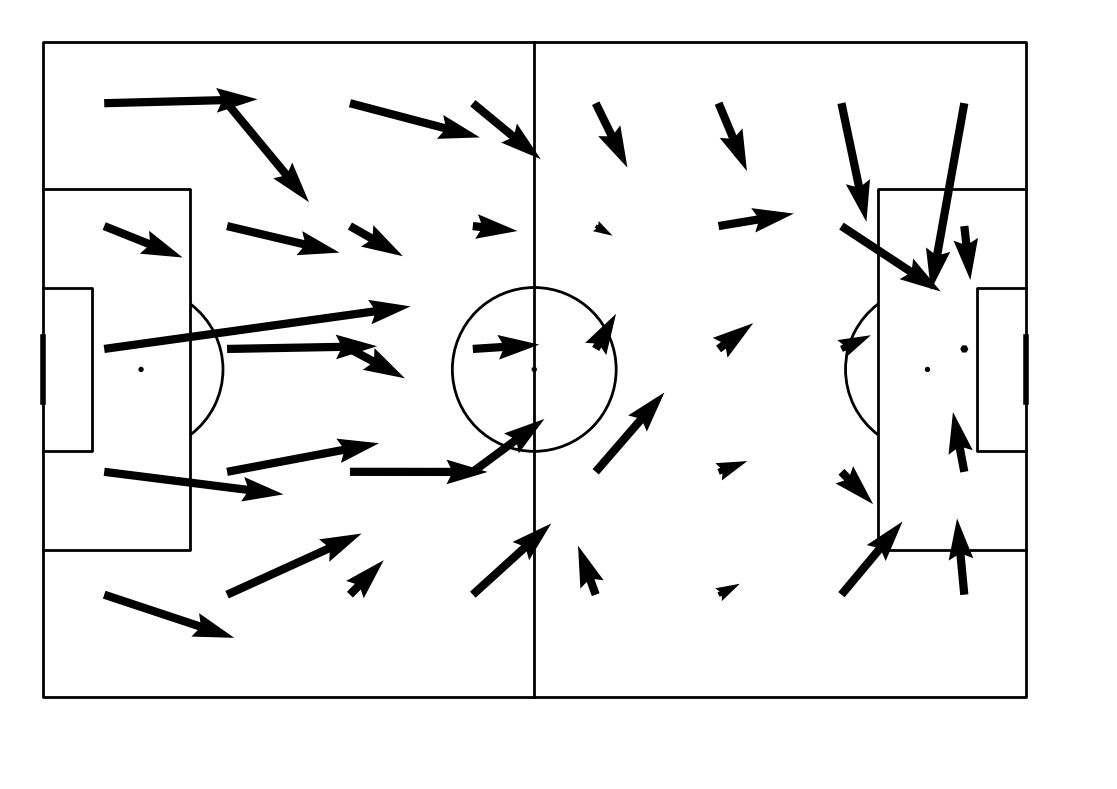

In [115]:


# Define starting points of each vector
start_points = np.array(Zone_centre)

# Define the vectors (directions and magnitudes)
vectors = np.array(Zone_action_net)

pitch=mplsoccer.Pitch(pitch_type='statsbomb',pitch_color='white',line_color='black')
fig,ax=pitch.draw(figsize=(14,8))

#fig,ax=pitch.draw(figsize=(14,8))

# Plot each vector starting from its specific start point
for start, vec in zip(start_points, vectors):
    ax.quiver(start[0], start[1], vec[0], vec[1], angles='xy', scale_units='xy', scale=1)
    
    
    
x_ticks = np.linspace(0,130,15)
y_ticks = np.linspace(0,90,15)

ax.set_xticks(x_ticks)
ax.set_yticks(y_ticks)

#ax.grid(True)


In [121]:


def plot_vector_field_and_derivatives(starts, vectors,
                                      pitch_length=120, pitch_width=80,
                                      grid_x_res=120, grid_y_res=80,
                                      interpolation_method='linear'):
    """
    Given starts and vectors as list of lists or numpy arrays,
    interpolate onto a regular grid and plot vector field,
    divergence, and curl on a StatsBomb pitch.

    Parameters:
    - starts: list of lists or (N,2) array-like, vector start points (x,y)
    - vectors: list of lists or (N,2) array-like, vector components (u,v)
    - pitch_length, pitch_width: pitch size, default 120 x 80
    - grid_x_res, grid_y_res: resolution of grid for interpolation
    - interpolation_method: 'linear', 'nearest', or 'cubic' for griddata
    """

    # Convert inputs to numpy arrays (works fine if input is list of lists)
    starts = np.asarray(starts)
    vectors = np.asarray(vectors)

    # Create regular pitch grid
    grid_x = np.linspace(0, pitch_length, grid_x_res)
    grid_y = np.linspace(0, pitch_width, grid_y_res)
    grid_X, grid_Y = np.meshgrid(grid_x, grid_y)

    U = vectors[:, 0]
    V = vectors[:, 1]

    # Interpolate scattered vectors onto grid
    U_grid = griddata(starts, U, (grid_X, grid_Y),
                      method=interpolation_method, fill_value=0)
    V_grid = griddata(starts, V, (grid_X, grid_Y),
                      method=interpolation_method, fill_value=0)

    dx = grid_x[1] - grid_x[0]
    dy = grid_y[1] - grid_y[0]

    dU_dy, dU_dx = np.gradient(U_grid, dy, dx)
    dV_dy, dV_dx = np.gradient(V_grid, dy, dx)

    divergence = dU_dx + dV_dy
    curl = dV_dx - dU_dy

    # Plotting
    fig, axs = plt.subplots(1, 3, figsize=(18, 6))

    step = max(grid_x_res // 20, 1)
    axs[0].quiver(grid_X[::step, ::step], grid_Y[::step, ::step],
                  U_grid[::step, ::step], V_grid[::step, ::step])
    axs[0].set_title('Vector Field on StatsBomb Pitch')
    axs[0].set_xlim(0, pitch_length)
    axs[0].set_ylim(0, pitch_width)
    axs[0].set_aspect('equal')
    axs[0].set_xlabel('X (length)')
    axs[0].set_ylabel('Y (width)')

    div_plot = axs[1].imshow(divergence, origin='lower',
                            extent=[0, pitch_length, 0, pitch_width],
                            cmap='RdBu', aspect='auto')
    axs[1].set_title('Divergence')
    fig.colorbar(div_plot, ax=axs[1])

    curl_plot = axs[2].imshow(curl, origin='lower',
                             extent=[0, pitch_length, 0, pitch_width],
                             cmap='RdBu', aspect='auto')
    axs[2].set_title('Curl')
    fig.colorbar(curl_plot, ax=axs[2])

    plt.tight_layout()
    plt.show()


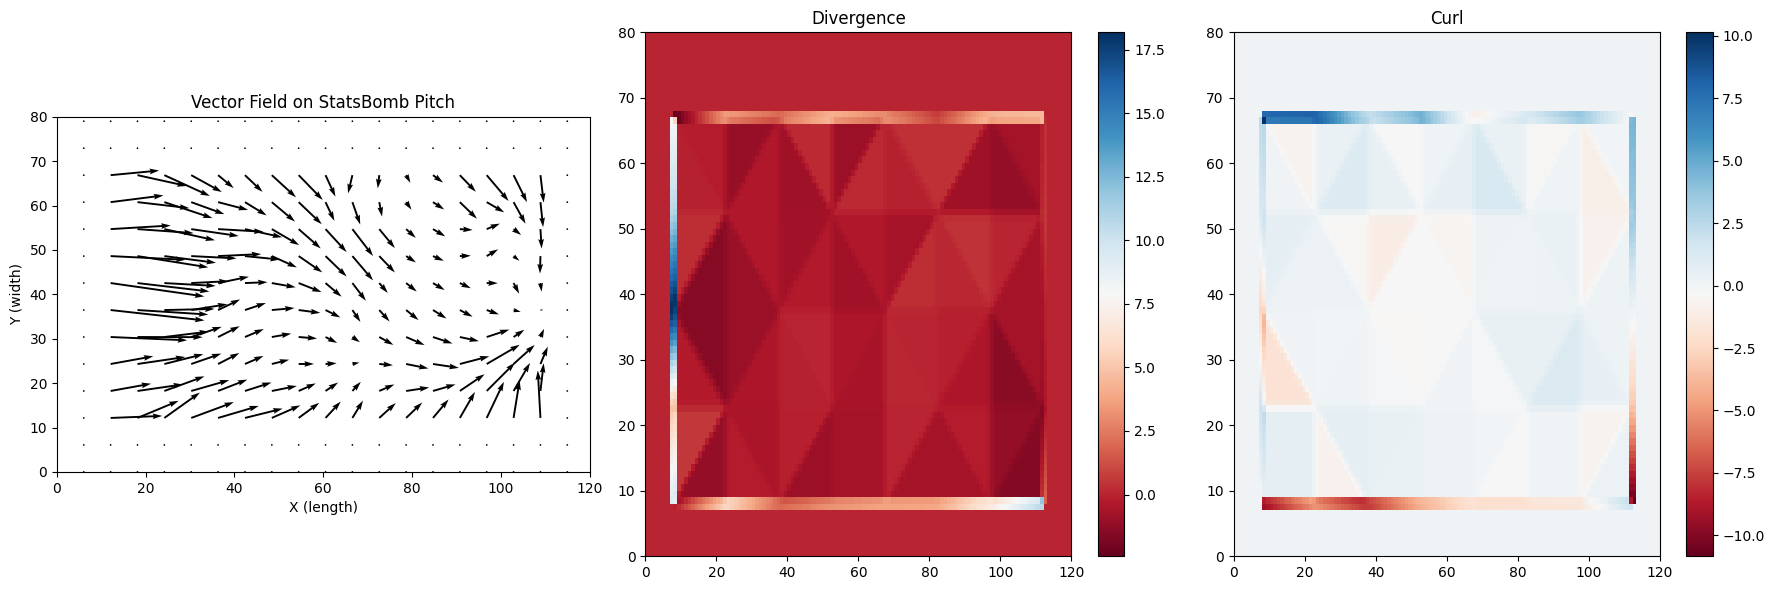

In [122]:
plot_vector_field_and_derivatives(Zone_centre, Zone_action_net)

In [125]:
def plot_vector_field_and_derivatives(starts, vectors,
                                      pitch_length=120, pitch_width=80,
                                      grid_x_res=120, grid_y_res=80,
                                      interpolation_method='linear'):
    """
    Given starts and vectors as list of lists or numpy arrays,
    interpolate onto a regular grid and plot vector field,
    divergence, and curl on a StatsBomb pitch.

    Parameters:
    - starts: list of lists or (N,2) array-like, vector start points (x,y)
    - vectors: list of lists or (N,2) array-like, vector components (u,v)
    - pitch_length, pitch_width: pitch size, default 120 x 80
    - grid_x_res, grid_y_res: resolution of grid for interpolation
    - interpolation_method: 'linear', 'nearest', or 'cubic' for griddata
    """

    # Convert inputs to numpy arrays (works fine if input is list of lists)
    starts = np.asarray(starts)
    vectors = np.asarray(vectors)

    # Create regular pitch grid
    grid_x = np.linspace(0, pitch_length, grid_x_res)
    grid_y = np.linspace(0, pitch_width, grid_y_res)
    grid_X, grid_Y = np.meshgrid(grid_x, grid_y)

    U = vectors[:, 0]
    V = vectors[:, 1]

    # Interpolate scattered vectors onto grid
    U_grid = griddata(starts, U, (grid_X, grid_Y),
                      method=interpolation_method, fill_value=0)
    V_grid = griddata(starts, V, (grid_X, grid_Y),
                      method=interpolation_method, fill_value=0)

    dx = grid_x[1] - grid_x[0]
    dy = grid_y[1] - grid_y[0]

    dU_dy, dU_dx = np.gradient(U_grid, dy, dx)
    dV_dy, dV_dx = np.gradient(V_grid, dy, dx)

    divergence = dU_dx + dV_dy
    curl = dV_dx - dU_dy

    # Plotting
    pitch=mplsoccer.Pitch(pitch_type='statsbomb',pitch_color='white',line_color='black')
    fig,axs=pitch.draw(figsize=(14,8))
    fig, axs = plt.subplots(1, 3, figsize=(18, 6))

    step = max(grid_x_res // 20, 1)
    axs[0].quiver(grid_X[::step, ::step], grid_Y[::step, ::step],
                  U_grid[::step, ::step], V_grid[::step, ::step])
    axs[0].set_title('Vector Field on StatsBomb Pitch')
    axs[0].set_xlim(0, pitch_length)
    axs[0].set_ylim(0, pitch_width)
    axs[0].set_aspect('equal')
    axs[0].set_xlabel('X (length)')
    axs[0].set_ylabel('Y (width)')

    div_plot = axs[1].imshow(divergence, origin='lower',
                            extent=[0, pitch_length, 0, pitch_width],
                            cmap='RdBu', aspect='auto')
    axs[1].set_title('Divergence')
    fig.colorbar(div_plot, ax=axs[1])

    curl_plot = axs[2].imshow(curl, origin='lower',
                             extent=[0, pitch_length, 0, pitch_width],
                             cmap='RdBu', aspect='auto')
    axs[2].set_title('Curl')
    fig.colorbar(curl_plot, ax=axs[2])

    plt.tight_layout()
    plt.show()

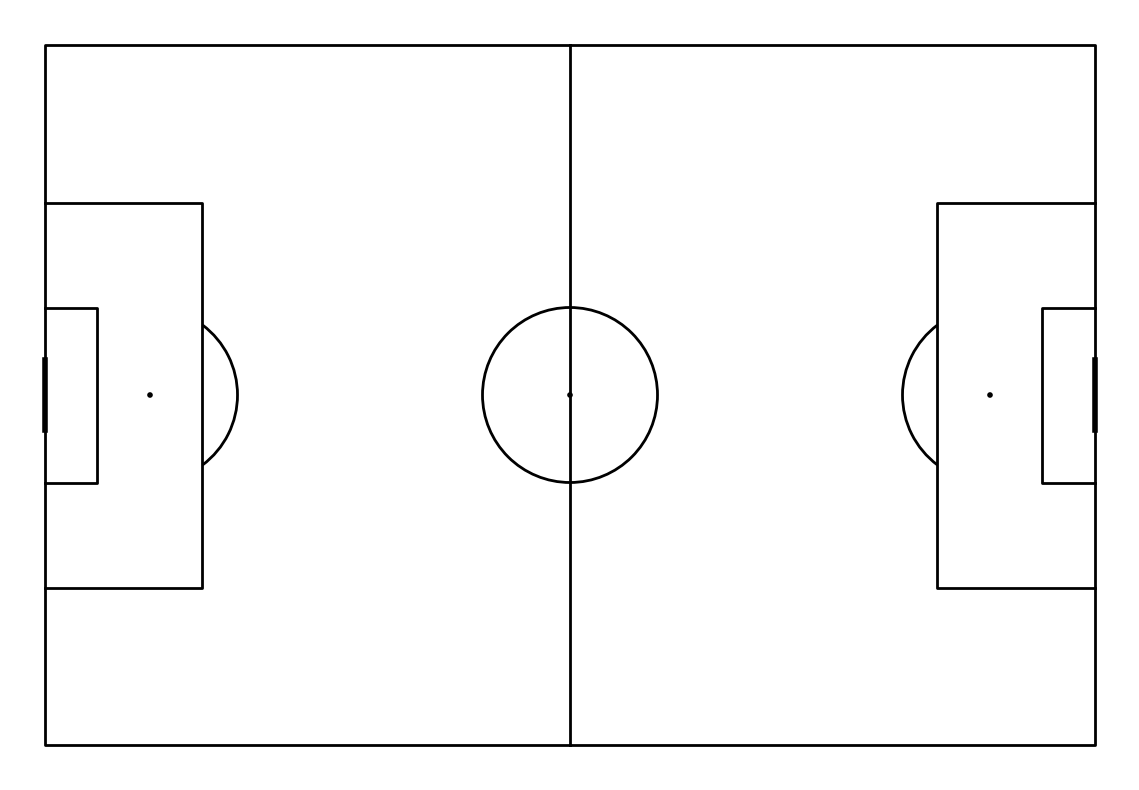

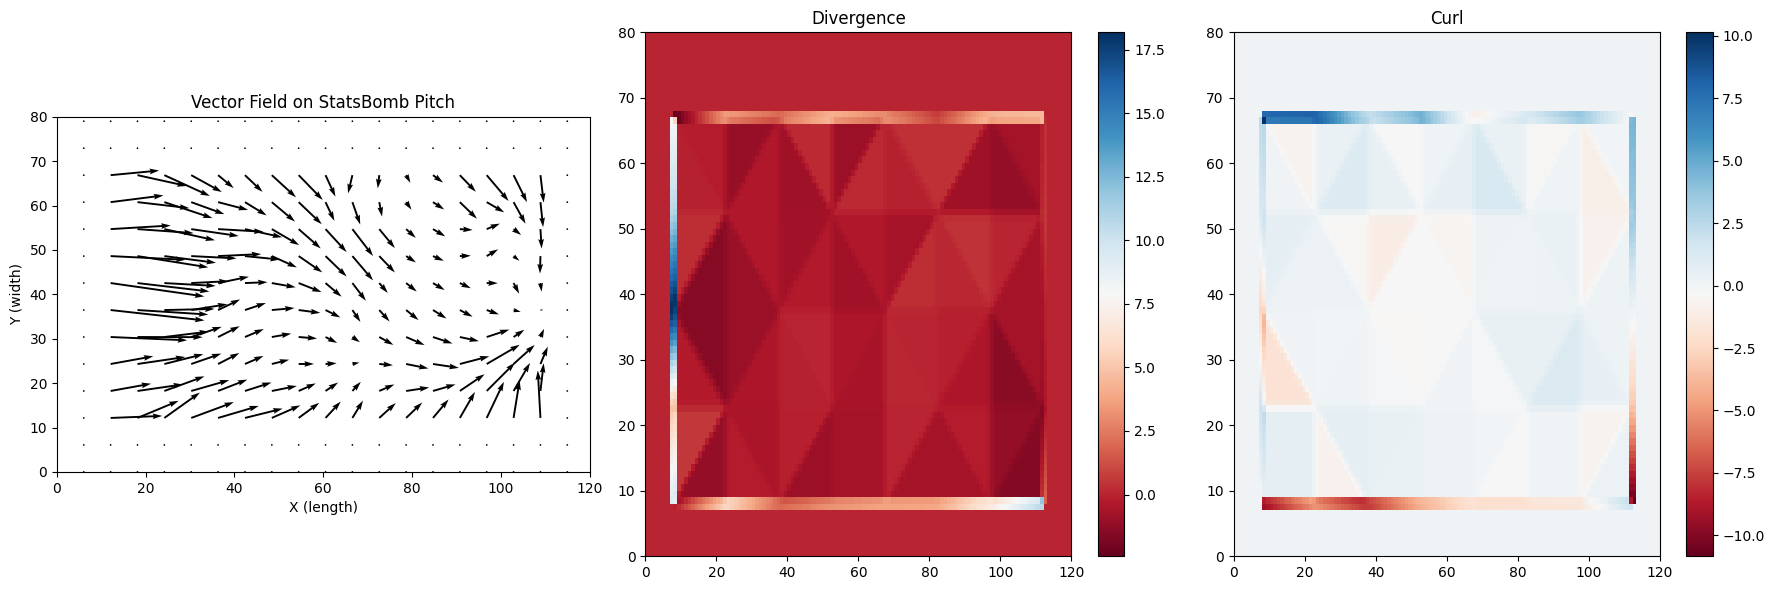

In [126]:
plot_vector_field_and_derivatives(Zone_centre, Zone_action_net)